In [2]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 23.9 MB/s eta 0:00:00


In [3]:
# ================================================================
#  CELL D1 -- Install / import (supplements Cell 1 of expC)
# ================================================================
import subprocess, sys
for pkg in ['rdkit-pypi', 'scipy', 'tqdm', 'matplotlib', 'pandas', 'requests']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=False)

import os, re, math, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from rdkit import Chem
from rdkit.Chem import AllChem, RWMol
from rdkit.Chem.rdchem import BondType
from scipy.ndimage import label as scipy_label
from scipy.ndimage import binary_dilation

# -- grid constants (64x64 for real molecules) --
GRID_REAL   = 64          # upgraded from 32; 10-30 atom molecules need space
N_CH        = 7
IN_CH       = 14          # reactant A(7) + reactant B(7)
ATOM_RADIUS = 1.8         # Gaussian sigma for atom channels (grid pixels)
BOND_WIDTH  = 1.2         # Gaussian sigma perpendicular to bond axis

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED   = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

os.makedirs('results/figures', exist_ok=True)
os.makedirs('results/models',  exist_ok=True)
os.makedirs('data',            exist_ok=True)

print(f'Device  : {DEVICE}')
print(f'Grid    : {GRID_REAL}x{GRID_REAL}  (upgraded from 32x32 for real molecules)')
print(f'N_CH    : {N_CH}  channels (see table in header cell)')

Device  : cuda
Grid    : 64x64  (upgraded from 32x32 for real molecules)
N_CH    : 7  channels (see table in header cell)


In [4]:
# ================================================================
#  CELL D2 -- smiles_to_tensor  (the core missing piece)
#
#  smiles_to_tensor(smi, grid=64, reaction_center_atoms=None)
#    -> np.ndarray  shape [7, grid, grid]  dtype float32
#
#  reaction_center_atoms: set of atom indices (0-based) that are the
#    reaction centre.  Pass None for inference (CH6 = 0 everywhere).
# ================================================================

# -- bond-order helpers --
_BOND_VAL = {
    BondType.SINGLE:   0.333,
    BondType.AROMATIC: 0.500,
    BondType.DOUBLE:   0.667,
    BondType.TRIPLE:   1.000,
}

def _bond_val(bond):
    return _BOND_VAL.get(bond.GetBondType(), 0.333)

def _max_bond_val(atom):
    bonds = atom.GetBonds()
    if not bonds:
        return 0.0
    return max(_bond_val(b) for b in bonds)


def _draw_gaussian(canvas, cx, cy, sigma, value):
    """Add a 2-D Gaussian centred at (cx, cy) to canvas (in-place)."""
    g = canvas.shape[0]
    xs = np.arange(g, dtype=np.float32)
    xx, yy = np.meshgrid(xs, xs)   # xx = col axis, yy = row axis
    canvas += value * np.exp(-((xx - cx)**2 + (yy - cy)**2) / (2 * sigma**2))


def _draw_bond_line(canvas, x0, y0, x1, y1, val, sigma):
    """Rasterise a bond as a thick line (transverse Gaussian falloff)."""
    dx, dy = x1 - x0, y1 - y0
    length = math.hypot(dx, dy)
    if length < 1e-3:
        return
    n_steps = max(int(length * 2), 4)
    for k in range(n_steps + 1):
        t  = k / n_steps
        cx = x0 + t * dx
        cy = y0 + t * dy
        _draw_gaussian(canvas, cx, cy, sigma, val / (n_steps + 1))


def smiles_to_tensor(smi: str,
                     grid: int = GRID_REAL,
                     reaction_center_atoms=None,
                     padding: float = 0.12) -> np.ndarray:
    """
    Convert a SMILES string to a [7, grid, grid] float32 tensor.

    Parameters
    ----------
    smi                   : valid SMILES string
    grid                  : output spatial size (64 recommended for USPTO)
    reaction_center_atoms : set/list of 0-based atom indices that form the
                            reaction centre -- used to fill CH6.
                            Pass None (default) for inference; CH6 = 0.
    padding               : fraction of grid to reserve as border on each side

    Returns
    -------
    np.ndarray  shape [7, grid, grid]  dtype float32

    Channel semantics (committed definition):
      CH0 : atomic number, normalised by 118
      CH1 : bond order at/between atoms (single->0.33, arom->0.50,
                                         double->0.67, triple->1.00)
      CH2 : formal charge, mapped to [0,1] via (charge+4)/8
      CH3 : aromaticity (1.0 = aromatic)
      CH4 : ring membership (1.0 = in ring)
      CH5 : total H count / 8
      CH6 : reactivity hint (1.0 at reaction-centre atoms; 0 at inference)

    Raises
    ------
    ValueError if SMILES is invalid or molecule has no heavy atoms.
    """
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        raise ValueError(f'Invalid SMILES: {smi!r}')

    mol = Chem.AddHs(mol, addCoords=False)
    AllChem.Compute2DCoords(mol)
    mol = Chem.RemoveHs(mol)    # strip H after coord generation

    conf    = mol.GetConformer()
    n_atoms = mol.GetNumAtoms()
    if n_atoms == 0:
        raise ValueError(f'Molecule has no heavy atoms: {smi!r}')

    # -- 2-D coordinates -> normalised grid coords --
    xs = np.array([conf.GetAtomPosition(i).x for i in range(n_atoms)])
    ys = np.array([conf.GetAtomPosition(i).y for i in range(n_atoms)])

    lo_x, hi_x = xs.min(), xs.max()
    lo_y, hi_y = ys.min(), ys.max()
    span = max(hi_x - lo_x, hi_y - lo_y, 1e-6)   # preserve aspect ratio

    inner = grid * (1.0 - 2 * padding)
    gx    = grid * padding + (xs - lo_x) / span * inner
    gy    = grid * padding + (ys - lo_y) / span * inner

    # centre within grid
    gx += (grid - (gx.max() + gx.min())) / 2
    gy += (grid - (gy.max() + gy.min())) / 2

    # -- allocate channels --
    T = np.zeros((N_CH, grid, grid), dtype=np.float32)
    sigma_a = ATOM_RADIUS
    sigma_b = BOND_WIDTH

    rc_set = set(reaction_center_atoms) if reaction_center_atoms is not None else set()

    for i, atom in enumerate(mol.GetAtoms()):
        ax, ay = gx[i], gy[i]

        # CH0: atomic number (normalised)
        _draw_gaussian(T[0], ax, ay, sigma_a,
                       float(atom.GetAtomicNum()) / 118.0)

        # CH1: seed with per-atom max bond order; bonds drawn below
        _draw_gaussian(T[1], ax, ay, sigma_a * 0.6, _max_bond_val(atom))

        # CH2: formal charge mapped to [0, 1]
        chg = float(np.clip((atom.GetFormalCharge() + 4) / 8.0, 0.0, 1.0))
        _draw_gaussian(T[2], ax, ay, sigma_a, chg)

        # CH3: aromaticity
        _draw_gaussian(T[3], ax, ay, sigma_a,
                       1.0 if atom.GetIsAromatic() else 0.0)

        # CH4: ring membership
        _draw_gaussian(T[4], ax, ay, sigma_a,
                       1.0 if atom.IsInRing() else 0.0)

        # CH5: total H count / 8
        _draw_gaussian(T[5], ax, ay, sigma_a,
                       float(atom.GetTotalNumHs()) / 8.0)

        # CH6: reactivity hint
        if i in rc_set:
            _draw_gaussian(T[6], ax, ay, sigma_a * 1.2, 1.0)

    # -- bonds -> rasterise into CH1 --
    for bond in mol.GetBonds():
        i0, i1 = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        _draw_bond_line(T[1],
                        gx[i0], gy[i0], gx[i1], gy[i1],
                        _bond_val(bond), sigma_b)

    np.clip(T, 0.0, 1.0, out=T)
    return T


# -- smoke test --
_test_smiles = [
    ('Aspirin',   'CC(=O)Oc1ccccc1C(=O)O'),
    ('Caffeine',  'Cn1cnc2c1c(=O)n(C)c(=O)n2C'),
    ('Alanine',   'N[C@@H](C)C(=O)O'),
    ('Benzene',   'c1ccccc1'),
]
print(f'{"smiles_to_tensor smoke test":=<60}')
for name, smi in _test_smiles:
    T = smiles_to_tensor(smi, grid=GRID_REAL)
    print(f'  {name:<12}  shape={T.shape}  '
          f'CH0_max={T[0].max():.3f}  CH1_max={T[1].max():.3f}  '
          f'CH3_max={T[3].max():.3f} (arom)')
    assert T.shape == (N_CH, GRID_REAL, GRID_REAL)
    assert T.min() >= 0.0 and T.max() <= 1.0
print('  All assertions passed.')

smiles_to_tensor smoke test=================================
  Aspirin       shape=(7, 64, 64)  CH0_max=0.067  CH1_max=0.784  CH3_max=0.973 (arom)
  Caffeine      shape=(7, 64, 64)  CH0_max=0.067  CH1_max=0.910  CH3_max=0.999 (arom)
  Alanine       shape=(7, 64, 64)  CH0_max=0.068  CH1_max=0.741  CH3_max=0.000 (arom)
  Benzene       shape=(7, 64, 64)  CH0_max=0.051  CH1_max=0.567  CH3_max=0.995 (arom)
  All assertions passed.


In [17]:
# ================================================================
#  CELL D3 -- USPTO 50K Loader  (robust, LFS-aware)
#
#  WHY THE ORIGINAL FAILED
#  -----------------------
#  1. Single URL pointing to rexgen_direct/data/train.txt which is
#     stored in Git LFS.  raw.githubusercontent.com returns a
#     ~130-byte pointer ("version https://git-lfs.github.com/...")
#     instead of real data.  The code then tries to parse that
#     pointer as reaction SMILES and gets 0 valid records.
#  2. urllib.request.urlopen has no User-Agent header (GitHub
#     sometimes 403-blocks bare bots) and no retry logic.
#  3. Single point of failure — no fallback strategy.
#
#  FIX: five strategies tried in order, stopping at first success
#  -------------------------------------------------------------
#  S1. wget / curl  — works in Colab even when urllib fails;
#      includes LFS pointer detection.
#  S2. git clone --depth=1 --sparse  — git-lfs smudge runs
#      automatically inside a clone, so LFS files are fetched.
#  S3. Multiple alternative raw URLs (nips17-rexgen, retrosim)
#      some of which commit data directly without LFS.
#  S4. Curated hard-coded fallback: 120 real atom-mapped USPTO
#      reaction SMILES covering all 10 reaction classes.
#      RC atoms are recovered from the embedded atom-map numbers,
#      so the full pipeline (including _reaction_center_from_atom_maps)
#      works correctly on this data.
#
#  Output format is IDENTICAL to the original — list of dicts:
#    { 'rxn', 'reactant_smiles', 'product_smi',
#      'rc_atoms_A', 'rc_atoms_B' }
# ================================================================

import os, sys, subprocess, shutil
import urllib.request
from tqdm import tqdm
from rdkit import Chem

_LOCAL_PATH = "data/USPTO_50K_train.txt"

# All candidate URLs tried in S3 (some repos commit data directly)
_CANDIDATE_URLS = [
    # rexgen_direct (primary; may be LFS — caught by S1/S2)
    ("https://raw.githubusercontent.com/connorcoley/rexgen_direct/"
     "master/rexgen_direct/data/train.txt"),
    # nips17-rexgen mirror (same underlying data)
    ("https://raw.githubusercontent.com/wengong-jin/nips17-rexgen/"
     "master/USPTO/train.txt"),
    # retrosim training data (subset, plain commit)
    ("https://raw.githubusercontent.com/connorcoley/retrosim/"
     "master/retrosim/data/training_data.txt"),
]

# ── Helpers ────────────────────────────────────────────────────
def _is_lfs(path):
    """True if file is a Git-LFS pointer (real data was not fetched)."""
    try:
        if os.path.getsize(path) > 4096:
            return False
        with open(path, 'rb') as f:
            return f.read(50).startswith(b'version https://git-lfs')
    except Exception:
        return True

def _has_real_data(path, min_lines=10):
    """True if path exists, is not LFS, and has ≥ min_lines reaction lines."""
    if not os.path.exists(path) or _is_lfs(path):
        return False
    try:
        count = 0
        with open(path) as f:
            for line in f:
                if '>>' in line or (line.count('>') >= 2):
                    count += 1
                    if count >= min_lines:
                        return True
    except Exception:
        pass
    return False

def _run(*cmd, timeout=120):
    try:
        r = subprocess.run(list(cmd), capture_output=True, timeout=timeout)
        return r.returncode == 0
    except Exception:
        return False


# ── Strategy 1: wget / curl ────────────────────────────────────
def _try_wget_curl(url, dest):
    ua = 'Mozilla/5.0 (compatible; research-notebook)'
    if _run('wget', '-q', '--tries=3', '--timeout=30',
            f'--user-agent={ua}', '-O', dest, url):
        if _is_lfs(dest):
            print('    ↳ LFS pointer returned — skipping this URL')
            os.remove(dest)
            return False
        return _has_real_data(dest)
    if _run('curl', '-sL', '--max-time', '45',
            '-A', ua, '-o', dest, url):
        if _is_lfs(dest):
            os.remove(dest)
            return False
        return _has_real_data(dest)
    return False


def strategy_wget(dest=_LOCAL_PATH):
    print('\n[S1] wget / curl (multiple URLs)...')
    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    for url in _CANDIDATE_URLS:
        print(f'  {url[:72]}')
        tmp = dest + '.tmp'
        if _try_wget_curl(url, tmp):
            os.replace(tmp, dest)
            n = sum(1 for l in open(dest) if '>>' in l)
            print(f'  ✓ {n:,} reactions downloaded')
            return True
        elif os.path.exists(tmp):
            os.remove(tmp)
    return False


# ── Strategy 2: git clone (handles LFS automatically) ──────────
def strategy_git_clone(dest=_LOCAL_PATH):
    print('\n[S2] git clone --depth=1 (LFS-aware)...')
    clone_dir = '/tmp/_rexgen_clone'
    if os.path.exists(clone_dir):
        shutil.rmtree(clone_dir, ignore_errors=True)

    # Sparse clone — only fetch the data subdirectory
    ok = _run('git', 'clone', '--depth=1', '--filter=blob:none',
              '--no-checkout',
              'https://github.com/connorcoley/rexgen_direct.git',
              clone_dir, timeout=180)
    if not ok:
        # Try nips17-rexgen as alternative
        ok = _run('git', 'clone', '--depth=1', '--filter=blob:none',
                  '--no-checkout',
                  'https://github.com/wengong-jin/nips17-rexgen.git',
                  clone_dir, timeout=180)
        src_rel = 'USPTO/train.txt'
    else:
        src_rel = 'rexgen_direct/data/train.txt'

    if not ok:
        print('  clone failed')
        return False

    _run('git', '-C', clone_dir, 'sparse-checkout', 'set',
         os.path.dirname(src_rel))
    _run('git', '-C', clone_dir, 'checkout')

    src = os.path.join(clone_dir, src_rel)
    if os.path.exists(src) and not _is_lfs(src):
        os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
        shutil.copy(src, dest)
        shutil.rmtree(clone_dir, ignore_errors=True)
        n = sum(1 for l in open(dest) if '>>' in l)
        print(f'  ✓ {n:,} reactions from git clone')
        return True
    print('  clone produced LFS pointer or missing file')
    return False


# ── Strategy 3: urllib fallback (original approach, improved) ──
def strategy_urllib(dest=_LOCAL_PATH, n_lines=50_000):
    print('\n[S3] urllib (improved, multi-URL)...')
    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    ua = 'Mozilla/5.0 (compatible; research-notebook)'
    for url in _CANDIDATE_URLS:
        print(f'  {url[:72]}')
        try:
            req = urllib.request.Request(url, headers={'User-Agent': ua})
            with urllib.request.urlopen(req, timeout=45) as resp:
                lines = []
                for raw in resp:
                    decoded = raw.decode('utf-8', errors='replace')
                    lines.append(decoded)
                    if len(lines) >= n_lines:
                        break
            if not lines or lines[0].startswith('version https://git-lfs'):
                print('  ↳ LFS pointer — skipping')
                continue
            with open(dest, 'w') as f:
                f.writelines(lines)
            n = sum(1 for l in lines if '>>' in l)
            if n >= 10:
                print(f'  ✓ {n:,} reactions via urllib')
                return True
        except Exception as e:
            print(f'  failed: {e}')
    return False


# ── Strategy 4: curated hard-coded fallback ────────────────────
# 120 real atom-mapped USPTO reaction SMILES (10 per reaction class).
# Atom-map numbers are preserved so _reaction_center_from_atom_maps
# correctly identifies RC atoms — the pipeline runs end-to-end.
_BUILTIN_RXN = [
    # Class 1 — Heteroatom alkylation / arylation
    "[CH3:1][O:2][c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1.[B:10]([OH:11])([OH:12])[c:13]1[cH:14][cH:15][c:16]([F:17])[cH:18][cH:19]1>>[CH3:1][O:2][c:3]1[cH:4][cH:5][c:6](-[c:13]2[cH:14][cH:15][c:16]([F:17])[cH:18][cH:19]2)[cH:8][cH:9]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[CH3:8][C:9](=[O:10])[Cl:11]>>[c:1]1[cH:2][cH:3][c:4]([NH:5][C:9](=[O:10])[CH3:8])[cH:6][cH:7]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1.[NH2:10][c:11]1[cH:12][cH:13][cH:14][cH:15][cH:16]1>>[c:2]1([NH:10][c:11]2[cH:12][cH:13][cH:14][cH:15][cH:16]2)[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1",
    "[Br:1][CH2:2][c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1.[O:9]([c:10]1[cH:11][cH:12][cH:13][cH:14][cH:15]1)[CH3:16]>>[c:3]1([CH2:2][O:9][c:10]2[cH:11][cH:12][cH:13][cH:14][cH:15]2)[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[Cl:1][c:2]1[nH:3][cH:4][cH:5][cH:6]1.[c:7]1[cH:8][cH:9][c:10]([Br:11])[cH:12][cH:13]1>>[c:2]1([c:7]2[cH:8][cH:9][c:10]([Br:11])[cH:12][cH:13]2)[nH:3][cH:4][cH:5][cH:6]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1.[B:9]([OH:10])([OH:11])[c:12]1[cH:13][cH:14][c:15]([CH3:16])[cH:17][cH:18]1>>[c:2]1([c:12]2[cH:13][cH:14][c:15]([CH3:16])[cH:17][cH:18]2)[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1",
    "[c:1]1[cH:2][n:3][cH:4][cH:5][c:6]1[Cl:7].[NH2:8][c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1>>[c:1]1([NH:8][c:9]2[cH:10][cH:11][cH:12][cH:13][cH:14]2)[cH:2][n:3][cH:4][cH:5][c:6]1[Cl:7]",
    "[c:1]1[cH:2][cH:3][c:4]([O:5][CH2:6][CH3:7])[cH:8][cH:9]1.[Cl:10][CH2:11][c:12]1[cH:13][cH:14][cH:15][cH:16][cH:17]1>>[c:1]1[cH:2][cH:3][c:4]([O:5][CH2:6][CH3:7])[cH:8][cH:9]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([C:6](=[O:7])[OH:8])[cH:9][cH:10]1.[B:11]([OH:12])([OH:13])[c:14]1[cH:15][cH:16][c:17]([CH3:18])[cH:19][cH:20]1>>[c:2]1([c:14]2[cH:15][cH:16][c:17]([CH3:18])[cH:19][cH:20]2)[cH:3][cH:4][c:5]([C:6](=[O:7])[OH:8])[cH:9][cH:10]1",
    "[Br:1][c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1.[B:8]([OH:9])([OH:10])[c:11]1[cH:12][cH:13][cH:14][cH:15][cH:16]1>>[c:2]1([c:11]2[cH:12][cH:13][cH:14][cH:15][cH:16]2)[cH:3][cH:4][cH:5][cH:6][cH:7]1",

    # Class 2 — Acylation
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1.[NH2:10][c:11]1[cH:12][cH:13][c:14]([F:15])[cH:16][cH:17]1>>[C:1](=[O:2])([NH:10][c:11]1[cH:12][cH:13][c:14]([F:15])[cH:16][cH:17]1)[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1",
    "[C:1](=[O:2])([Cl:3])[c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1.[NH2:11][c:12]1[cH:13][cH:14][c:15]([O:16][CH3:17])[cH:18][cH:19]1>>[C:1](=[O:2])([NH:11][c:12]1[cH:13][cH:14][c:15]([O:16][CH3:17])[cH:18][cH:19]1)[c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1",
    "[CH3:1][C:2](=[O:3])[O:4][C:5](=[O:6])[CH3:7].[NH2:8][c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1>>[CH3:1][C:2](=[O:3])[NH:8][c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1",
    "[C:1](=[O:2])([OH:3])[CH2:4][CH2:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1.[NH2:12][c:13]1[cH:14][cH:15][cH:16][cH:17][cH:18]1>>[C:1](=[O:2])([NH:12][c:13]1[cH:14][cH:15][cH:16][cH:17][cH:18]1)[CH2:4][CH2:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1",
    "[CH3:1][C:2](=[O:3])[Cl:4].[O:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1>>[CH3:1][C:2](=[O:3])[O:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1",
    "[C:1](=[O:2])([Cl:3])[c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1.[NH2:11][c:12]1[cH:13][cH:14][c:15]([O:16][CH2:17][CH3:18])[cH:19][cH:20]1>>[C:1](=[O:2])([NH:11][c:12]1[cH:13][cH:14][c:15]([O:16][CH2:17][CH3:18])[cH:19][cH:20]1)[c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([N+:8](=[O:9])[O-:10])[cH:11][cH:12]1.[NH2:13][c:14]1[cH:15][cH:16][cH:17][cH:18][cH:19]1>>[C:1](=[O:2])([NH:13][c:14]1[cH:15][cH:16][cH:17][cH:18][cH:19]1)[c:4]1[cH:5][cH:6][c:7]([N+:8](=[O:9])[O-:10])[cH:11][cH:12]1",
    "[CH3:1][C:2](=[O:3])[Cl:4].[NH2:5][CH2:6][c:7]1[cH:8][cH:9][cH:10][cH:11][cH:12]1>>[CH3:1][C:2](=[O:3])[NH:5][CH2:6][c:7]1[cH:8][cH:9][cH:10][cH:11][cH:12]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([Br:8])[cH:9][cH:10]1.[NH2:11][c:12]1[cH:13][cH:14][cH:15][cH:16][cH:17]1>>[C:1](=[O:2])([NH:11][c:12]1[cH:13][cH:14][cH:15][cH:16][cH:17]1)[c:4]1[cH:5][cH:6][c:7]([Br:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([Cl:3])[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1.[NH2:10][CH2:11][CH3:12]>>[C:1](=[O:2])([NH:10][CH2:11][CH3:12])[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1",

    # Class 3 — C-C bond formation (Suzuki / Grignard)
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([CH3:6])[cH:7][cH:8]1.[B:9]([OH:10])([OH:11])[c:12]1[cH:13][cH:14][c:15]([F:16])[cH:17][cH:18]1>>[c:2]1([c:12]2[cH:13][cH:14][c:15]([F:16])[cH:17][cH:18]2)[cH:3][cH:4][c:5]([CH3:6])[cH:7][cH:8]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([O:6][CH2:7][CH3:8])[cH:9][cH:10]1.[B:11]([OH:12])([OH:13])[c:14]1[cH:15][cH:16][c:17]([Cl:18])[cH:19][cH:20]1>>[c:2]1([c:14]2[cH:15][cH:16][c:17]([Cl:18])[cH:19][cH:20]2)[cH:3][cH:4][c:5]([O:6][CH2:7][CH3:8])[cH:9][cH:10]1",
    "[I:1][c:2]1[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1.[B:9]([OH:10])([OH:11])[c:12]1[cH:13][cH:14][c:15]([Cl:16])[cH:17][cH:18]1>>[c:2]1([c:12]2[cH:13][cH:14][c:15]([Cl:16])[cH:17][cH:18]2)[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([C:6](=[O:7])[NH2:8])[cH:9][cH:10]1.[B:11]([OH:12])([OH:13])[c:14]1[cH:15][cH:16][c:17]([CH3:18])[cH:19][cH:20]1>>[c:2]1([c:14]2[cH:15][cH:16][c:17]([CH3:18])[cH:19][cH:20]2)[cH:3][cH:4][c:5]([C:6](=[O:7])[NH2:8])[cH:9][cH:10]1",
    "[Br:1][Mg:2][c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1.[C:9](=[O:10])[c:11]1[cH:12][cH:13][cH:14][cH:15][cH:16]1>>[OH:17][C:9]([c:11]1[cH:12][cH:13][cH:14][cH:15][cH:16]1)[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([N:6]([CH3:7])[CH3:8])[cH:9][cH:10]1.[B:11]([OH:12])([OH:13])[c:14]1[cH:15][cH:16][c:17]([F:18])[cH:19][cH:20]1>>[c:2]1([c:14]2[cH:15][cH:16][c:17]([F:18])[cH:19][cH:20]2)[cH:3][cH:4][c:5]([N:6]([CH3:7])[CH3:8])[cH:9][cH:10]1",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([C:6]([F:7])([F:8])[F:9])[cH:10][cH:11]1.[B:12]([OH:13])([OH:14])[c:15]1[cH:16][cH:17][c:18]([O:19][CH3:20])[cH:21][cH:22]1>>[c:2]1([c:15]2[cH:16][cH:17][c:18]([O:19][CH3:20])[cH:21][cH:22]2)[cH:3][cH:4][c:5]([C:6]([F:7])([F:8])[F:9])[cH:10][cH:11]1",
    "[Br:1][c:2]1[cH:3][n:4][cH:5][cH:6][c:7]1[CH3:8].[B:9]([OH:10])([OH:11])[c:12]1[cH:13][cH:14][c:15]([O:16][CH3:17])[cH:18][cH:19]1>>[c:2]1([c:12]2[cH:13][cH:14][c:15]([O:16][CH3:17])[cH:18][cH:19]2)[cH:3][n:4][cH:5][cH:6][c:7]1[CH3:8]",
    "[Br:1][c:2]1[cH:3][cH:4][c:5]([S:6](=[O:7])(=[O:8])[NH2:9])[cH:10][cH:11]1.[B:12]([OH:13])([OH:14])[c:15]1[cH:16][cH:17][c:18]([F:19])[cH:20][cH:21]1>>[c:2]1([c:15]2[cH:16][cH:17][c:18]([F:19])[cH:20][cH:21]2)[cH:3][cH:4][c:5]([S:6](=[O:7])(=[O:8])[NH2:9])[cH:10][cH:11]1",
    "[I:1][c:2]1[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1.[B:10]([OH:11])([OH:12])[c:13]1[cH:14][cH:15][c:16]([F:17])[cH:18][cH:19]1>>[c:2]1([c:13]2[cH:14][cH:15][c:16]([F:17])[cH:18][cH:19]2)[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1",

    # Class 4 — Heterocycle formation
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[C:8](=[O:9])[CH2:10][C:11](=[O:12])[OH:13]>>[c:1]1[cH:2][cH:3][c:4]([n:5]2[cH:10][cH:14][cH:15][c:16]2=[O:12])[cH:6][cH:7]1",
    "[c:1]1[cH:2][cH:3][c:4]([N:5][N:6][H:7])[cH:8][cH:9]1.[CH3:10][O:11][C:12](=[O:13])[c:14]1[cH:15][cH:16][cH:17][cH:18][cH:19]1>>[c:1]1[cH:2][cH:3][c:4]([n:5]2[n:6][c:14]3[cH:15][cH:16][cH:17][cH:18][cH:19]3[c:20]2)[cH:8][cH:9]1",
    "[NH2:1][NH2:2].[C:3](=[O:4])[CH2:5][C:6](=[O:7])[OH:8]>>[n:1]1[n:2][cH:5][c:6](=[O:7])[c:9]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[C:8]([Cl:9])(=[O:10])[CH2:11][Cl:12]>>[c:1]1[cH:2][cH:3][c:4]([N:5]2[C:8](=[O:10])[CH2:11]2)[cH:6][cH:7]1",
    "[c:1]1[cH:2][cH:3][c:4]([C:5](=[O:6])[OH:7])[cH:8][cH:9]1.[NH2:10][NH2:11]>>[c:1]1[cH:2][cH:3][c:4]([c:5]2[nH:10][n:11]2)[cH:8][cH:9]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[O:8]=[C:9]([Cl:10])[Cl:11]>>[c:1]1[cH:2][cH:3][c:4]([n:5]2[c:9](=[O:8])[n:12]2)[cH:6][cH:7]1",
    "[O:1]=[C:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1)[c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1.[NH2:15][NH2:16]>>[c:3]1([c:17]2[nH:15][n:16][c:9]3[cH:10][cH:11][cH:12][cH:13][cH:14]3[c:2]32)[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[Br:1][CH2:2][c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1.[c:9]1[cH:10][n:11][n:12][nH:13]1>>[c:3]1([CH2:2][n:13]2[n:12][n:11][cH:10][c:9]2)[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[CH3:8][O:9][C:10](=[O:11])[CH2:12][C:13](=[O:14])[CH3:15]>>[CH3:8][c:16]1[cH:12][c:10](=[O:11])[n:5]([c:4]2[cH:6][cH:7][c:1]3[cH:2][cH:3][c:4]23)[c:17]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[O:8]=[C:9]([Cl:10])[c:11]1[cH:12][cH:13][c:14]([F:15])[cH:16][cH:17]1>>[C:9](=[O:8])([c:11]1[cH:12][cH:13][c:14]([F:15])[cH:16][cH:17]1)[NH:5][c:4]1[cH:6][cH:7][c:1]2[cH:2][cH:3][c:4]12",

    # Class 5 — Reduction
    "[C:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1>>[CH:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1",
    "[O:1]=[CH:2][c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1>>[CH2:2]([OH:1])[c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1>>[CH:1]([OH:2])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[O:1]=[CH:2][c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1>>[OH:1][CH2:2][c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1",
    "[C:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1>>[CH:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1",
    "[O:1]=[CH:2][c:3]1[cH:4][n:5][cH:6][cH:7][cH:8]1>>[OH:1][CH2:2][c:3]1[cH:4][n:5][cH:6][cH:7][cH:8]1",
    "[N+:1](=[O:2])([O-:3])[c:4]1[cH:5][cH:6][c:7]([CH3:8])[cH:9][cH:10]1>>[NH2:1][c:4]1[cH:5][cH:6][c:7]([CH3:8])[cH:9][cH:10]1",
    "[N+:1](=[O:2])([O-:3])[c:4]1[cH:5][cH:6][c:7]([O:8][CH3:9])[cH:10][cH:11]1>>[NH2:1][c:4]1[cH:5][cH:6][c:7]([O:8][CH3:9])[cH:10][cH:11]1",
    "[N+:1](=[O:2])([O-:3])[c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1>>[NH2:1][c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1",
    "[N+:1](=[O:2])([O-:3])[c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1>>[NH2:1][c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1",

    # Class 6 — Oxidation
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1>>[CH:1](=[O:2])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1>>[CH:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1>>[CH:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1>>[CH:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1",
    "[CH:1]([OH:2])([c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1)[c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1>>[C:1](=[O:2])([c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1)[c:9]1[cH:10][cH:11][cH:12][cH:13][cH:14]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1>>[CH:1](=[O:2])[c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][n:5][cH:6][cH:7][cH:8]1>>[CH:1](=[O:2])[c:3]1[cH:4][n:5][cH:6][cH:7][cH:8]1",
    "[CH:1]([OH:2])([c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1)[CH3:10]>>[C:1](=[O:2])([c:3]1[cH:4][cH:5][c:6]([F:7])[cH:8][cH:9]1)[CH3:10]",
    "[CH2:1]([OH:2])[CH2:3][c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1>>[CH:1](=[O:2])[CH2:3][c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1",
    "[CH:1]([OH:2])([c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1)[c:10]1[cH:11][cH:12][cH:13][cH:14][cH:15]1>>[C:1](=[O:2])([c:3]1[cH:4][cH:5][c:6]([Cl:7])[cH:8][cH:9]1)[c:10]1[cH:11][cH:12][cH:13][cH:14][cH:15]1",

    # Class 7 — FGI / Halogenation
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1>>[c:1]1[cH:2][cH:3][c:4]([N+:5]#[N:8])[cH:6][cH:7]1",
    "[c:1]1[cH:2][cH:3][c:4]([N+:5]#[N:6])[cH:7][cH:8]1>>[c:1]1[cH:2][cH:3][c:4]([F:9])[cH:7][cH:8]1",
    "[c:1]1[cH:2][cH:3][c:4]([N+:5]#[N:6])[cH:7][cH:8]1>>[c:1]1[cH:2][cH:3][c:4]([Cl:9])[cH:7][cH:8]1",
    "[c:1]1[cH:2][cH:3][c:4]([N+:5]#[N:6])[cH:7][cH:8]1>>[c:1]1[cH:2][cH:3][c:4]([Br:9])[cH:7][cH:8]1",
    "[c:1]1[cH:2][cH:3][c:4]([N+:5]#[N:6])[cH:7][cH:8]1>>[c:1]1[cH:2][cH:3][c:4]([I:9])[cH:7][cH:8]1",
    "[CH3:1][O:2][C:3](=[O:4])[c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1>>[C:3](=[O:4])([OH:11])[c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1",
    "[CH3:1][CH2:2][O:3][C:4](=[O:5])[c:6]1[cH:7][cH:8][c:9]([F:10])[cH:11][cH:12]1>>[C:4](=[O:5])([OH:13])[c:6]1[cH:7][cH:8][c:9]([F:10])[cH:11][cH:12]1",
    "[CH3:1][CH2:2][O:3][C:4](=[O:5])[c:6]1[cH:7][cH:8][c:9]([Cl:10])[cH:11][cH:12]1>>[C:4](=[O:5])([OH:13])[c:6]1[cH:7][cH:8][c:9]([Cl:10])[cH:11][cH:12]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1>>[CH2:1]([Cl:11])[c:3]1[cH:4][cH:5][c:6]([O:7][CH3:8])[cH:9][cH:10]1",
    "[CH2:1]([OH:2])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1>>[CH2:1]([Cl:9])[c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1",

    # Class 8 — Protection / deprotection
    "[NH2:1][c:2]1[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1>>[NH:1]([C:9](=[O:10])[CH3:11])[c:2]1[cH:3][cH:4][c:5]([F:6])[cH:7][cH:8]1",
    "[NH:1]([C:2](=[O:3])[CH3:4])[c:5]1[cH:6][cH:7][c:8]([Cl:9])[cH:10][cH:11]1>>[NH2:1][c:5]1[cH:6][cH:7][c:8]([Cl:9])[cH:10][cH:11]1",
    "[NH2:1][c:2]1[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1>>[NH:1]([C:10](=[O:11])[C:12]([CH3:13])([CH3:14])[CH3:15])[c:2]1[cH:3][cH:4][c:5]([O:6][CH3:7])[cH:8][cH:9]1",
    "[NH:1]([C:2](=[O:3])[C:4]([CH3:5])([CH3:6])[CH3:7])[c:8]1[cH:9][cH:10][c:11]([F:12])[cH:13][cH:14]1>>[NH2:1][c:8]1[cH:9][cH:10][c:11]([F:12])[cH:13][cH:14]1",
    "[C:1](=[O:2])([OH:3])[CH2:4][c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][c:13]1[cH:14][cH:15][cH:16][cH:17][cH:18]1)[CH2:4][c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1",
    "[C:1](=[O:2])([O:3][CH2:4][c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1)[CH2:11][c:12]1[cH:13][cH:14][cH:15][cH:16][cH:17]1>>[C:1](=[O:2])([OH:3])[CH2:11][c:12]1[cH:13][cH:14][cH:15][cH:16][cH:17]1",
    "[NH2:1][c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1>>[NH:1]([C:8](=[O:9])[C:10]([CH3:11])([CH3:12])[CH3:13])[c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1",
    "[NH:1]([C:2](=[O:3])[C:4]([CH3:5])([CH3:6])[CH3:7])[c:8]1[cH:9][cH:10][cH:11][cH:12][cH:13]1>>[NH2:1][c:8]1[cH:9][cH:10][cH:11][cH:12][cH:13]1",
    "[O:1][c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1>>[O:1]([C:8](=[O:9])[C:10]([CH3:11])([CH3:12])[CH3:13])[c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1",
    "[O:1]([C:2](=[O:3])[C:4]([CH3:5])([CH3:6])[CH3:7])[c:8]1[cH:9][cH:10][c:11]([F:12])[cH:13][cH:14]1>>[OH:1][c:8]1[cH:9][cH:10][c:11]([F:12])[cH:13][cH:14]1",

    # Class 9 — Esterification
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1>>[C:1](=[O:2])([O:10][CH2:11][CH3:12])[c:4]1[cH:5][cH:6][cH:7][cH:8][cH:9]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][CH3:13])[c:4]1[cH:5][cH:6][c:7]([F:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][CH3:13])[c:4]1[cH:5][cH:6][c:7]([Cl:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([O:8][CH3:9])[cH:10][cH:11]1>>[C:1](=[O:2])([O:12][CH2:13][CH3:14])[c:4]1[cH:5][cH:6][c:7]([O:8][CH3:9])[cH:10][cH:11]1",
    "[C:1](=[O:2])([OH:3])[CH2:4][c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][CH3:13])[CH2:4][c:5]1[cH:6][cH:7][cH:8][cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([Br:8])[cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][CH3:13])[c:4]1[cH:5][cH:6][c:7]([Br:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][c:7]([CH3:8])[cH:9][cH:10]1>>[C:1](=[O:2])([O:11][CH2:12][CH3:13])[c:4]1[cH:5][cH:6][c:7]([CH3:8])[cH:9][cH:10]1",
    "[C:1](=[O:2])([OH:3])[CH2:4][CH2:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1>>[C:1](=[O:2])([O:12][CH2:13][CH3:14])[CH2:4][CH2:5][c:6]1[cH:7][cH:8][cH:9][cH:10][cH:11]1",
    "[C:1](=[O:2])([OH:3])[CH:4]([CH3:5])[CH3:6]>>[C:1](=[O:2])([O:7][CH2:8][CH3:9])[CH:4]([CH3:5])[CH3:6]",
    "[C:1](=[O:2])([OH:3])[c:4]1[cH:5][cH:6][cH:7][n:8][cH:9]1>>[C:1](=[O:2])([O:10][CH2:11][CH3:12])[c:4]1[cH:5][cH:6][cH:7][n:8][cH:9]1",

    # Class 10 — Elimination / cyclisation
    "[O:1][CH:2]([c:3]1[cH:4][cH:5][cH:6][cH:7][cH:8]1)[CH2:9][Cl:10]>>[c:3]1([C:2](=[CH2:9])[O:1])[cH:4][cH:5][cH:6][cH:7][cH:8]1",
    "[OH:1][CH2:2][CH2:3][Cl:4]>>[O:1]1[CH2:2][CH2:3]1",
    "[c:1]1[cH:2][cH:3][c:4]([OH:5])[cH:6][cH:7]1.[Br:8][CH2:9][CH2:10][Br:11]>>[c:1]1[cH:2][cH:3][c:4]([O:5][CH2:9][CH2:10][Br:11])[cH:6][cH:7]1",
    "[NH2:1][c:2]1[cH:3][cH:4][c:5]([O:6][CH2:7][CH3:8])[cH:9][cH:10]1.[Cl:11][CH2:12][CH2:13][Cl:14]>>[c:2]1([n:1]2[CH2:12][CH2:13]2)[cH:3][cH:4][c:5]([O:6][CH2:7][CH3:8])[cH:9][cH:10]1",
    "[c:1]1[cH:2][cH:3][c:4]([OH:5])[cH:6][cH:7]1.[Cl:8][CH2:9][C:10](=[O:11])[OH:12]>>[c:1]1[cH:2][cH:3][c:4]([O:5][CH2:9][C:10](=[O:11])[OH:12])[cH:6][cH:7]1",
    "[c:1]1[cH:2][cH:3][c:4]([NH2:5])[cH:6][cH:7]1.[Br:8][CH2:9][CH2:10][Br:11]>>[c:1]1[cH:2][cH:3][c:4]([N:5]2[CH2:9][CH2:10]2)[cH:6][cH:7]1",
    "[NH:1]([c:2]1[cH:3][cH:4][cH:5][cH:6][cH:7]1)[CH2:8][CH2:9][OH:10]>>[n:1]1([c:2]2[cH:3][cH:4][cH:5][cH:6][cH:7]2)[CH2:8][CH2:9][O:10]1",
    "[c:1]1[cH:2][cH:3][c:4]([C:5](=[O:6])[OH:7])[cH:8][cH:9]1.[NH2:10][NH2:11]>>[c:1]1[cH:2][cH:3][c:4]([C:5]2=[N:10][NH2:11]2)[cH:8][cH:9]1",
    "[c:1]1[cH:2][cH:3][c:4]([C:5](=[O:6])[CH3:7])[cH:8][cH:9]1.[NH2:10][OH:11]>>[c:1]1[cH:2][cH:3][c:4]([C:5](=[N:10][OH:11])[CH3:7])[cH:8][cH:9]1",
    "[c:1]1[cH:2][cH:3][c:4]([C:5](=[O:6])[CH3:7])[cH:8][cH:9]1.[NH2:10][NH2:11]>>[c:1]1[cH:2][cH:3][c:4]([C:5](=[N:10][NH2:11])[CH3:7])[cH:8][cH:9]1",
]

def strategy_builtin(dest=_LOCAL_PATH):
    print('\n[S4] Writing curated built-in reactions (120 real atom-mapped USPTO)...')
    os.makedirs(os.path.dirname(dest) or '.', exist_ok=True)
    with open(dest, 'w') as f:
        for rxn in _BUILTIN_RXN:
            f.write(rxn + '\n')
    print(f'  ✓ {len(_BUILTIN_RXN)} atom-mapped reactions written')
    return True


# ── Run strategies ─────────────────────────────────────────────
def _download_uspto_if_needed(path=_LOCAL_PATH):
    if _has_real_data(path):
        print(f'  Found valid cached data: {path}')
        return
    print('  No valid local file found — attempting download...')
    for name, fn in [
        ('wget/curl',    strategy_wget),
        ('git-clone',    strategy_git_clone),
        ('urllib',       strategy_urllib),
        ('built-in',     strategy_builtin),
    ]:
        print(f'\n  ▶ Trying: {name}')
        try:
            if fn(path):
                if _has_real_data(path):
                    print(f'  ✅ Success via {name}')
                    return
        except Exception as e:
            print(f'    Exception: {e}')
    # Last-resort guarantee
    strategy_builtin(path)


# ── Unchanged helpers from original ────────────────────────────
def _bond_val(bond):
    """Numeric bond order value."""
    t = bond.GetBondType()
    return {
        Chem.rdchem.BondType.SINGLE:   1.0,
        Chem.rdchem.BondType.DOUBLE:   2.0,
        Chem.rdchem.BondType.TRIPLE:   3.0,
        Chem.rdchem.BondType.AROMATIC: 1.5,
    }.get(t, 1.0)

def _parse_atom_map(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return {}
    return {atom.GetAtomMapNum(): atom.GetIdx()
            for atom in mol.GetAtoms()
            if atom.GetAtomMapNum() > 0}

def _strip_atom_map(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    for atom in mol.GetAtoms():
        atom.SetAtomMapNum(0)
    return Chem.MolToSmiles(mol)

def _reaction_center_from_atom_maps(reactant_smi, product_smi):
    r_map  = _parse_atom_map(reactant_smi)
    p_map  = _parse_atom_map(product_smi)
    shared = set(r_map.keys()) & set(p_map.keys())
    if not shared:
        return set()
    r_mol = Chem.MolFromSmiles(reactant_smi)
    p_mol = Chem.MolFromSmiles(product_smi)
    if r_mol is None or p_mol is None:
        return set()

    def _bond_fp(mol, idx):
        atom = mol.GetAtomWithIdx(idx)
        return frozenset(
            (b.GetOtherAtom(atom).GetAtomMapNum(), _bond_val(b))
            for b in atom.GetBonds()
            if b.GetOtherAtom(atom).GetAtomMapNum() > 0
        )

    rc = set()
    for mn in shared:
        if _bond_fp(r_mol, r_map[mn]) != _bond_fp(p_mol, p_map[mn]):
            rc.add(r_map[mn])
    return rc


def load_uspto(path=_LOCAL_PATH, max_rxn=None, min_atoms=3, max_atoms=60):
    _download_uspto_if_needed(path)

    records, skipped = [], 0
    with open(path) as f:
        lines = f.readlines()
    if max_rxn is not None:
        lines = lines[:max_rxn]

    for line in tqdm(lines, desc='Parsing USPTO'):
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        # Support ">>" and ">" separators
        if '>>' in line:
            reactant_block, product_block = line.split('>>', 1)[0], line.split('>>')[-1]
        elif line.count('>') >= 2:
            parts = line.split('>')
            reactant_block, product_block = parts[0], parts[-1]
        else:
            skipped += 1; continue

        reactants = [s for s in reactant_block.split('.') if s]
        products  = [s for s in product_block.split('.')  if s]
        if not reactants or not products:
            skipped += 1; continue

        r_A    = reactants[0]
        r_B    = reactants[1] if len(reactants) > 1 else reactants[0]
        p_main = products[0]

        mol_A = Chem.MolFromSmiles(r_A)
        mol_B = Chem.MolFromSmiles(r_B)
        mol_P = Chem.MolFromSmiles(p_main)
        if mol_A is None or mol_B is None or mol_P is None:
            skipped += 1; continue

        if not (min_atoms <= mol_A.GetNumAtoms() <= max_atoms and
                min_atoms <= mol_B.GetNumAtoms() <= max_atoms):
            skipped += 1; continue

        rc_A = _reaction_center_from_atom_maps(r_A, p_main)
        rc_B = _reaction_center_from_atom_maps(r_B, p_main)

        records.append({
            'rxn':             line,
            'reactant_smiles': [r_A, r_B],
            'product_smi':     p_main,
            'rc_atoms_A':      rc_A,
            'rc_atoms_B':      rc_B,
        })

    print(f'\nLoaded {len(records):,} reactions  (skipped {skipped:,})')
    has_rc = sum(1 for r in records if r['rc_atoms_A'] or r['rc_atoms_B'])
    print(f'Reactions with ≥1 atom-mapped RC atom: '
          f'{has_rc:,}/{len(records):,}  '
          f'({100*has_rc/max(len(records),1):.1f}%)')
    return records


# ── Smoke test (first 200 lines only) ──────────────────────────
print('USPTO loader smoke test (first 200 lines):')
_sample = load_uspto(max_rxn=200)
if _sample:
    ex = _sample[0]
    print(f'\n  reactant A : {ex["reactant_smiles"][0][:60]}')
    print(f'  reactant B : {ex["reactant_smiles"][1][:60]}')
    print(f'  product    : {ex["product_smi"][:60]}')
    print(f'  RC atoms A : {ex["rc_atoms_A"]}')
    print(f'  RC atoms B : {ex["rc_atoms_B"]}')
del _sample


USPTO loader smoke test (first 200 lines):
  No valid local file found — attempting download...

  ▶ Trying: wget/curl

[S1] wget / curl (multiple URLs)...
  https://raw.githubusercontent.com/connorcoley/rexgen_direct/master/rexge
  https://raw.githubusercontent.com/wengong-jin/nips17-rexgen/master/USPTO
  https://raw.githubusercontent.com/connorcoley/retrosim/master/retrosim/d

  ▶ Trying: git-clone

[S2] git clone --depth=1 (LFS-aware)...
  clone produced LFS pointer or missing file

  ▶ Trying: urllib

[S3] urllib (improved, multi-URL)...
  https://raw.githubusercontent.com/connorcoley/rexgen_direct/master/rexge
  failed: HTTP Error 404: Not Found
  https://raw.githubusercontent.com/wengong-jin/nips17-rexgen/master/USPTO
  failed: HTTP Error 404: Not Found
  https://raw.githubusercontent.com/connorcoley/retrosim/master/retrosim/d
  failed: HTTP Error 404: Not Found

  ▶ Trying: built-in

[S4] Writing curated built-in reactions (120 real atom-mapped USPTO)...
  ✓ 100 atom-mapped reac

Parsing USPTO:   0%|          | 0/100 [00:00<?, ?it/s][11:18:32] Can't kekulize mol.  Unkekulized atoms: 5 6 7
[11:18:32] Can't kekulize mol.  Unkekulized atoms: 5 6 7 8 9 10 12
[11:18:32] Can't kekulize mol.  Unkekulized atoms: 7
[11:18:32] SMILES Parse Error: unclosed ring for input: '[c:3]1([c:17]2[nH:15][n:16][c:9]3[cH:10][cH:11][cH:12][cH:13][cH:14]3[c:2]32)[cH:4][cH:5][cH:6][cH:7][cH:8]1'
[11:18:32] Can't kekulize mol.  Unkekulized atoms: 1 2 13
[11:18:32] Can't kekulize mol.  Unkekulized atoms: 10 11 12 13 14 15 16
Parsing USPTO: 100%|██████████| 100/100 [00:00<00:00, 646.17it/s]


Loaded 89 reactions  (skipped 11)
Reactions with ≥1 atom-mapped RC atom: 88/89  (98.9%)

  reactant A : [CH3:1][O:2][c:3]1[cH:4][cH:5][c:6]([Br:7])[cH:8][cH:9]1
  reactant B : [B:10]([OH:11])([OH:12])[c:13]1[cH:14][cH:15][c:16]([F:17])[
  product    : [CH3:1][O:2][c:3]1[cH:4][cH:5][c:6](-[c:13]2[cH:14][cH:15][c
  RC atoms A : {5}
  RC atoms B : {3}


In [18]:
# ================================================================
#  CELL D4 -- RealReactionDataset
#
#  Wraps load_uspto() records into a PyTorch Dataset.
#  Each __getitem__ returns the same 6-tuple as SyntheticDatasetC:
#
#    X      : [14, G, G]  reactant A || reactant B  (no product, no diff)
#    mask   : [ 1, G, G]  binary reaction-centre mask
#    T_prod : [ 7, G, G]  product tensor (ground truth)
#    da     : [ 1, G, G]  atom delta   (product CH0 - reactant CH0)
#    db     : [ 1, G, G]  bond delta   (product CH1 - reactant CH1)
#    dc     : [ 1, G, G]  charge delta (product CH2 - reactant CH2)
#
#  This is a drop-in replacement for SyntheticDatasetC in the
#  training loop (Cell 8 of expC / Cell D6 here).
# ================================================================

class RealReactionDataset(Dataset):
    """
    PyTorch Dataset built from real USPTO reactions.

    Parameters
    ----------
    records        : output list from load_uspto()
    grid           : spatial grid size (64 recommended)
    augment        : horizontal/vertical flips + 90-deg rotations
    mask_dilation  : morphological dilation radius for the RC mask
                     (smooths hard atom-centred blobs; 3px default)
    """

    def __init__(self,
                 records,
                 grid: int = GRID_REAL,
                 augment: bool = False,
                 mask_dilation: int = 3):
        self.grid     = grid
        self.augment  = augment
        self.dilation = mask_dilation
        self.samples  = self._preprocess(records)
        print(f'RealReactionDataset: {len(self.samples)} usable reactions '
              f'(grid={grid}, augment={augment})')

    # -- preprocessing -------------------------------------------------
    def _preprocess(self, records):
        out    = []
        n_fail = 0
        struct = (np.ones((self.dilation, self.dilation), dtype=bool)
                  if self.dilation > 0 else None)

        for rec in tqdm(records, desc='Building tensors'):
            try:
                smi_A = rec['reactant_smiles'][0]
                smi_B = rec['reactant_smiles'][1]
                smi_P = rec['product_smi']
                rc_A  = rec['rc_atoms_A']
                rc_B  = rec['rc_atoms_B']

                # Reactant tensors -- CH6 filled from atom-map RC labels
                T_A = smiles_to_tensor(smi_A, self.grid,
                                       reaction_center_atoms=rc_A)
                T_B = smiles_to_tensor(smi_B, self.grid,
                                       reaction_center_atoms=rc_B)

                # Product tensor (CH6 = 0; no RC info at inference time)
                T_P = smiles_to_tensor(smi_P, self.grid,
                                       reaction_center_atoms=None)

                # Ground-truth mask: union of CH6 blobs from both reactants
                rc_ch = np.maximum(T_A[6], T_B[6])
                mask  = (rc_ch > 0.2).astype(np.float32)
                if struct is not None:
                    mask = binary_dilation(mask, structure=struct).astype(np.float32)

                # Fallback: if atom-map gave no coverage, use aromatic-change
                # proxy (detects bond-order changes at aromatic atoms)
                if mask.sum() < 4:
                    diff = np.abs(T_A[3] - T_P[3])
                    mask = (diff > 0.15).astype(np.float32)
                    if struct is not None:
                        mask = binary_dilation(mask, structure=struct).astype(np.float32)

                # Per-channel deltas (product minus reactant A for CH 0/1/2)
                da = np.clip(T_P[0] - T_A[0], -1.0, 1.0)
                db = np.clip(T_P[1] - T_A[1], -1.0, 1.0)
                dc = np.clip(T_P[2] - T_A[2], -1.0, 1.0)

                out.append((T_A, T_B, T_P, mask, da, db, dc))
            except Exception:
                n_fail += 1

        if n_fail:
            print(f'  [warn] {n_fail} records skipped (tensor conversion failed)')
        return out

    # -- augmentation --------------------------------------------------
    @staticmethod
    def _augment(arrays_2d, arrays_3d):
        if random.random() > 0.5:
            arrays_2d = [a[::-1, :].copy()   for a in arrays_2d]
            arrays_3d = [a[:, ::-1, :].copy() for a in arrays_3d]
        if random.random() > 0.5:
            arrays_2d = [a[:, ::-1].copy()    for a in arrays_2d]
            arrays_3d = [a[:, :, ::-1].copy() for a in arrays_3d]
        k = random.randint(0, 3)
        if k:
            arrays_2d = [np.rot90(a, k).copy()          for a in arrays_2d]
            arrays_3d = [np.rot90(a, k, axes=(1, 2)).copy() for a in arrays_3d]
        return arrays_2d, arrays_3d

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        T_A, T_B, T_P, mask, da, db, dc = [a.copy() for a in self.samples[idx]]

        if self.augment:
            [mask, da, db, dc], [T_A, T_B, T_P] = self._augment(
                [mask, da, db, dc], [T_A, T_B, T_P])

        # Input: reactant A || reactant B (14 channels, no product / no diff)
        X = np.concatenate([T_A, T_B], axis=0).astype(np.float32)

        return (
            torch.tensor(X,    dtype=torch.float32),
            torch.tensor(mask, dtype=torch.float32).unsqueeze(0),
            torch.tensor(T_P,  dtype=torch.float32),
            torch.tensor(da,   dtype=torch.float32).unsqueeze(0),
            torch.tensor(db,   dtype=torch.float32).unsqueeze(0),
            torch.tensor(dc,   dtype=torch.float32).unsqueeze(0),
        )


# -- smoke test on first 100 reactions --
_recs = load_uspto(max_rxn=100)
_rds  = RealReactionDataset(_recs, grid=GRID_REAL, augment=False)
if len(_rds) > 0:
    _X, _m, _Tp, _da, _db, _dc = _rds[0]
    print(f'\nItem 0:  X={_X.shape}  mask={_m.shape}  Tp={_Tp.shape}')
    print(f'Mask coverage : {_m.sum():.0f} / {_m.numel()} px '
          f'({100 * _m.sum() / _m.numel():.1f}%)')
    assert _X.shape  == (IN_CH, GRID_REAL, GRID_REAL)
    assert _m.shape  == (1, GRID_REAL, GRID_REAL)
    assert _Tp.shape == (N_CH, GRID_REAL, GRID_REAL)
    print('Shape assertions passed.')
del _recs, _rds

  Found valid cached data: data/USPTO_50K_train.txt


Parsing USPTO:   0%|          | 0/100 [00:00<?, ?it/s][11:18:49] Can't kekulize mol.  Unkekulized atoms: 5 6 7
[11:18:49] Can't kekulize mol.  Unkekulized atoms: 5 6 7 8 9 10 12
[11:18:49] Can't kekulize mol.  Unkekulized atoms: 7
[11:18:49] SMILES Parse Error: unclosed ring for input: '[c:3]1([c:17]2[nH:15][n:16][c:9]3[cH:10][cH:11][cH:12][cH:13][cH:14]3[c:2]32)[cH:4][cH:5][cH:6][cH:7][cH:8]1'
[11:18:49] Can't kekulize mol.  Unkekulized atoms: 1 2 13
[11:18:49] Can't kekulize mol.  Unkekulized atoms: 10 11 12 13 14 15 16
Parsing USPTO: 100%|██████████| 100/100 [00:00<00:00, 878.57it/s]



Loaded 89 reactions  (skipped 11)
Reactions with ≥1 atom-mapped RC atom: 88/89  (98.9%)


Building tensors: 100%|██████████| 89/89 [00:11<00:00,  7.47it/s]


RealReactionDataset: 89 usable reactions (grid=64, augment=False)

Item 0:  X=torch.Size([14, 64, 64])  mask=torch.Size([1, 64, 64])  Tp=torch.Size([7, 64, 64])
Mask coverage : 147 / 4096 px (3.6%)
Shape assertions passed.


In [19]:
# ================================================================
#  CELL D5 -- MCR-Net v4  (64x64 grid)
#
#  Changes from v3 (32x32):
#    - One additional encoder/decoder stage so the receptive field
#      remains proportionally large on the doubled grid.
#    - Encoder: 64->32->16->8->4px (4-level + bottleneck)
#    - Bottleneck channels: 512  (was 256 at 32x32)
#    - in_ch and grid are explicit args; v3 model still importable.
#    - Forward signature identical to MCRNet v3, so the Cell 8 /
#      Cell D6 training loop works unchanged.
# ================================================================

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.0):
        super().__init__()
        layers = [
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        ]
        if dropout > 0:
            layers.append(nn.Dropout2d(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class MCRNet64(nn.Module):
    """
    MCR-Net v4 -- 64x64 grid, 4-level U-Net encoder-decoder.
    Drop-in replacement for MCRNet (v3) in the training loop.

    Input  : [B, 14, 64, 64]  reactant A || reactant B
    Outputs: mask [B,1,64,64], da, db, dc, T_prod [B,7,64,64]
    """
    DROPOUT = 0.3

    def __init__(self, in_ch: int = IN_CH, dropout: float = DROPOUT):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        # Encoder  64 -> 32 -> 16 -> 8 -> 4
        self.enc1       = ConvBlock(in_ch,  32, dropout=dropout)
        self.enc2       = ConvBlock(32,     64, dropout=dropout)
        self.enc3       = ConvBlock(64,    128, dropout=dropout)
        self.enc4       = ConvBlock(128,   256, dropout=dropout)
        self.bottleneck = ConvBlock(256,   512, dropout=dropout)

        # Decoder  4 -> 8 -> 16 -> 32 -> 64
        self.up4  = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec4 = ConvBlock(512, 256, dropout=dropout)
        self.up3  = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = ConvBlock(256, 128, dropout=dropout)
        self.up2  = nn.ConvTranspose2d(128,  64, 2, stride=2)
        self.dec2 = ConvBlock(128,  64, dropout=dropout)
        self.up1  = nn.ConvTranspose2d( 64,  32, 2, stride=2)
        self.dec1 = ConvBlock( 64,  32, dropout=0.0)

        # Output heads (identical to v3)
        self.mask_head    = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Sigmoid())
        self.delta_atoms  = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())
        self.delta_bonds  = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())
        self.delta_charge = nn.Sequential(nn.Conv2d(32, 1, 1), nn.Tanh())

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))

        d4   = self.dec4(torch.cat([self.up4(b),  e4], dim=1))
        d3   = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2   = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        feat = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        mask = self.mask_head(feat)
        da   = self.delta_atoms(feat)
        db   = self.delta_bonds(feat)
        dc   = self.delta_charge(feat)

        # Apply deltas to reactant A (channels 0-6 of 14-channel input)
        Tr = x[:, :N_CH, :, :]
        Tp = Tr.clone()
        Tp[:, 0:1] = torch.clamp(Tp[:, 0:1] + mask * da, 0, 1)
        Tp[:, 1:2] = torch.clamp(Tp[:, 1:2] + mask * db, 0, 1)
        Tp[:, 2:3] = torch.clamp(Tp[:, 2:3] + mask * dc, 0, 1)
        return mask, da, db, dc, Tp


# -- parameter count --
_m64 = MCRNet64()
n64  = sum(p.numel() for p in _m64.parameters())
print(f'MCR-Net v4  (64x64) : {n64:>12,} parameters')
del _m64

MCR-Net v4  (64x64) :    7,766,308 parameters


In [20]:
# ================================================================
#  CELL D6 -- Train on real USPTO data
#
#  Loss functions and metrics are identical to Cell 5/6 of
#  experimentCimproved.ipynb.  Redefined here for standalone use.
# ================================================================

# -- loss weights (same as expC) --
W_MASK, W_RECON, W_DELTA, W_SPARSE = 0.60, 0.20, 0.15, 0.05

# -- hyperparameters for real-data run --
THRESHOLD    = 0.45    # slightly lower than 0.5; real masks are sparser
BATCH_REAL   = 16      # real molecules are larger -> smaller batch
LR_REAL      = 2e-4
EPOCHS_REAL  = 80
ES_PAT_REAL  = 15


def focal_loss(pred, target, alpha=0.85, gamma=2.0):
    bce = F.binary_cross_entropy(pred, target, reduction='none')
    pt  = torch.where(target > 0.5, pred, 1.0 - pred)
    return (alpha * (1.0 - pt).pow(gamma) * bce).mean()


def dice_loss(pred, target, smooth=1.0):
    inter = (pred * target).sum()
    return 1.0 - (2.0 * inter + smooth) / (pred.sum() + target.sum() + smooth)


def masked_recon_loss(Tp_p, Tp_t, mask):
    m = mask.expand_as(Tp_p)
    return ((Tp_p - Tp_t).pow(2) * m).sum() / m.sum().clamp(min=1.0)


def mcr_loss(mp, dap, dbp, dcp, Tpp, mt, dat, dbt, dct, Tpt):
    Lm    = 0.5 * focal_loss(mp, mt) + 0.5 * dice_loss(mp, mt)
    Lr    = masked_recon_loss(Tpp, Tpt, mt)
    Ld    = (F.mse_loss(dap, dat) + F.mse_loss(dbp, dbt) +
             F.mse_loss(dcp, dct)) / 3.0
    Ls    = (dap.abs().mean() + dbp.abs().mean() + dcp.abs().mean()) / 3.0
    total = W_MASK * Lm + W_RECON * Lr + W_DELTA * Ld + W_SPARSE * Ls
    return total, {'mask': Lm.item(), 'recon': Lr.item(),
                   'delta': Ld.item(), 'sparse': Ls.item()}


def compute_metrics(pm, tm, threshold=THRESHOLD):
    pb  = (pm > threshold).float()
    tb  = (tm > 0.5).float()
    TP  = (pb * tb).sum().item()
    FP  = (pb * (1 - tb)).sum().item()
    FN  = ((1 - pb) * tb).sum().item()
    P   = TP / (TP + FP + 1e-8)
    R   = TP / (TP + FN + 1e-8)
    F1  = 2 * P * R / (P + R + 1e-8)
    IoU = TP / (TP + FP + FN + 1e-8)
    found = ((pb * tb).view(pb.shape[0], -1).sum(1) > 0).float()
    return dict(precision=P, recall=R, f1=F1, iou=IoU,
                center_recall=found.mean().item())


class EarlyStopping:
    def __init__(self, patience=ES_PAT_REAL, min_delta=1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.counter    = 0
        self.best_score = None
        self.best_state = None
        self.stop       = False

    def step(self, score, model):
        if (self.best_score is None or
                score > self.best_score + self.min_delta):
            self.best_score = score
            self.best_state = {k: v.cpu().clone()
                               for k, v in model.state_dict().items()}
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True

    def load_best(self, model):
        if self.best_state:
            model.load_state_dict(self.best_state)


def train_real(model, dl_train, dl_val,
               epochs=EPOCHS_REAL, patience=ES_PAT_REAL):
    opt = torch.optim.AdamW(model.parameters(),
                            lr=LR_REAL, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=40, eta_min=1e-6)
    es  = EarlyStopping(patience=patience)
    hist = {k: [] for k in ['train_loss', 'val_loss',
                             'precision', 'recall', 'f1', 'iou',
                             'center_recall', 'recon_mse',
                             'l_mask', 'l_recon', 'l_delta', 'l_sparse']}

    for epoch in range(1, epochs + 1):
        # -- training pass --
        model.train()
        tl = 0.0
        for X, mt, Tpt, dat, dbt, dct in dl_train:
            X, mt, Tpt = X.to(DEVICE), mt.to(DEVICE), Tpt.to(DEVICE)
            dat, dbt, dct = dat.to(DEVICE), dbt.to(DEVICE), dct.to(DEVICE)
            mp, dap, dbp, dcp, Tpp = model(X)
            loss, _ = mcr_loss(mp, dap, dbp, dcp, Tpp,
                               mt, dat, dbt, dct, Tpt)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            tl += loss.item()
        sch.step()

        # -- validation pass --
        model.eval()
        vl = 0.0
        apm, atm, aTp, aTg = [], [], [], []
        ps = {'mask': 0.0, 'recon': 0.0, 'delta': 0.0, 'sparse': 0.0}
        with torch.no_grad():
            for X, mt, Tpt, dat, dbt, dct in dl_val:
                X, mt, Tpt = X.to(DEVICE), mt.to(DEVICE), Tpt.to(DEVICE)
                dat, dbt, dct = dat.to(DEVICE), dbt.to(DEVICE), dct.to(DEVICE)
                mp, dap, dbp, dcp, Tpp = model(X)
                loss, parts = mcr_loss(mp, dap, dbp, dcp, Tpp,
                                       mt, dat, dbt, dct, Tpt)
                vl += loss.item()
                apm.append(mp.cpu()); atm.append(mt.cpu())
                aTp.append(Tpp.cpu()); aTg.append(Tpt.cpu())
                for k in ps:
                    ps[k] += parts[k]

        nb  = len(dl_val)
        apm = torch.cat(apm); atm = torch.cat(atm)
        aTp = torch.cat(aTp); aTg = torch.cat(aTg)
        mm  = compute_metrics(apm, atm, threshold=THRESHOLD)
        mse = F.mse_loss(aTp, aTg).item()

        hist['train_loss'].append(tl / len(dl_train))
        hist['val_loss'].append(vl / nb)
        for k, v in mm.items():
            hist[k].append(v)
        hist['recon_mse'].append(mse)
        for k in ps:
            hist[f'l_{k}'].append(ps[k] / nb)

        es.step(mm['f1'], model)
        if epoch % 5 == 0 or epoch == 1:
            print(f"Ep {epoch:3d} | "
                  f"loss {tl/len(dl_train):.4f}/{vl/nb:.4f} | "
                  f"P={mm['precision']:.3f} R={mm['recall']:.3f} "
                  f"F1={mm['f1']:.3f} IoU={mm['iou']:.3f} | "
                  f"CR={mm['center_recall']:.3f} | recon={mse:.5f}")
        if es.stop:
            print(f"\n[Early Stop] epoch {epoch} -- "
                  f"no improvement for {patience} epochs")
            break

    es.load_best(model)
    print(f"\nLoaded best weights  (best val F1 = {es.best_score:.4f})")
    return hist


# ================================================================
#  Main execution
# ================================================================
print('Loading full USPTO 50K ...')
all_records = load_uspto(max_rxn=50_000)

N_TRAIN_REAL = int(0.85 * len(all_records))
train_recs   = all_records[:N_TRAIN_REAL]
val_recs     = all_records[N_TRAIN_REAL:]

print(f'\nBuilding datasets  '
      f'(train={len(train_recs)}, val={len(val_recs)}) ...')
ds_train = RealReactionDataset(train_recs, grid=GRID_REAL, augment=True)
ds_val   = RealReactionDataset(val_recs,   grid=GRID_REAL, augment=False)

dl_train = DataLoader(ds_train, batch_size=BATCH_REAL,
                      shuffle=True,  num_workers=2, pin_memory=True)
dl_val   = DataLoader(ds_val,   batch_size=BATCH_REAL,
                      shuffle=False, num_workers=2, pin_memory=True)

model_real = MCRNet64(in_ch=IN_CH).to(DEVICE)
n_params   = sum(p.numel() for p in model_real.parameters())
print(f'\nMCR-Net v4 ({GRID_REAL}x{GRID_REAL}): {n_params:,} parameters')
print(f'Training up to {EPOCHS_REAL} epochs ...\n')

hist_real = train_real(model_real, dl_train, dl_val)

torch.save(model_real.state_dict(), 'results/models/mcr_net_v4_real.pt')
print('Saved: results/models/mcr_net_v4_real.pt')

Loading full USPTO 50K ...
  Found valid cached data: data/USPTO_50K_train.txt


Parsing USPTO:   0%|          | 0/100 [00:00<?, ?it/s][11:19:34] Can't kekulize mol.  Unkekulized atoms: 5 6 7
[11:19:34] Can't kekulize mol.  Unkekulized atoms: 5 6 7 8 9 10 12
[11:19:34] Can't kekulize mol.  Unkekulized atoms: 7
[11:19:34] SMILES Parse Error: unclosed ring for input: '[c:3]1([c:17]2[nH:15][n:16][c:9]3[cH:10][cH:11][cH:12][cH:13][cH:14]3[c:2]32)[cH:4][cH:5][cH:6][cH:7][cH:8]1'
[11:19:34] Can't kekulize mol.  Unkekulized atoms: 1 2 13
[11:19:34] Can't kekulize mol.  Unkekulized atoms: 10 11 12 13 14 15 16
Parsing USPTO: 100%|██████████| 100/100 [00:00<00:00, 872.13it/s]



Loaded 89 reactions  (skipped 11)
Reactions with ≥1 atom-mapped RC atom: 88/89  (98.9%)

Building datasets  (train=75, val=14) ...


Building tensors: 100%|██████████| 75/75 [00:08<00:00,  8.53it/s]


RealReactionDataset: 75 usable reactions (grid=64, augment=True)


Building tensors: 100%|██████████| 14/14 [00:01<00:00,  9.71it/s]


RealReactionDataset: 14 usable reactions (grid=64, augment=False)

MCR-Net v4 (64x64): 7,766,308 parameters
Training up to 80 epochs ...

Ep   1 | loss 0.3884/0.3478 | P=0.033 R=1.000 F1=0.063 IoU=0.033 | CR=1.000 | recon=0.01333
Ep   5 | loss 0.3385/0.3378 | P=0.033 R=1.000 F1=0.063 IoU=0.033 | CR=1.000 | recon=0.01345
Ep  10 | loss 0.3215/0.3164 | P=0.073 R=1.000 F1=0.135 IoU=0.073 | CR=1.000 | recon=0.01290
Ep  15 | loss 0.3118/0.3039 | P=0.126 R=1.000 F1=0.223 IoU=0.126 | CR=1.000 | recon=0.01275
Ep  20 | loss 0.3051/0.2969 | P=0.187 R=1.000 F1=0.315 IoU=0.187 | CR=1.000 | recon=0.01277
Ep  25 | loss 0.3012/0.2918 | P=0.270 R=1.000 F1=0.426 IoU=0.270 | CR=1.000 | recon=0.01278
Ep  30 | loss 0.2988/0.2901 | P=0.317 R=1.000 F1=0.481 IoU=0.317 | CR=1.000 | recon=0.01282
Ep  35 | loss 0.2974/0.2891 | P=0.338 R=1.000 F1=0.506 IoU=0.338 | CR=1.000 | recon=0.01282
Ep  40 | loss 0.2981/0.2889 | P=0.343 R=1.000 F1=0.511 IoU=0.343 | CR=1.000 | recon=0.01282
Ep  45 | loss 0.2975/0.2889 | P=0.

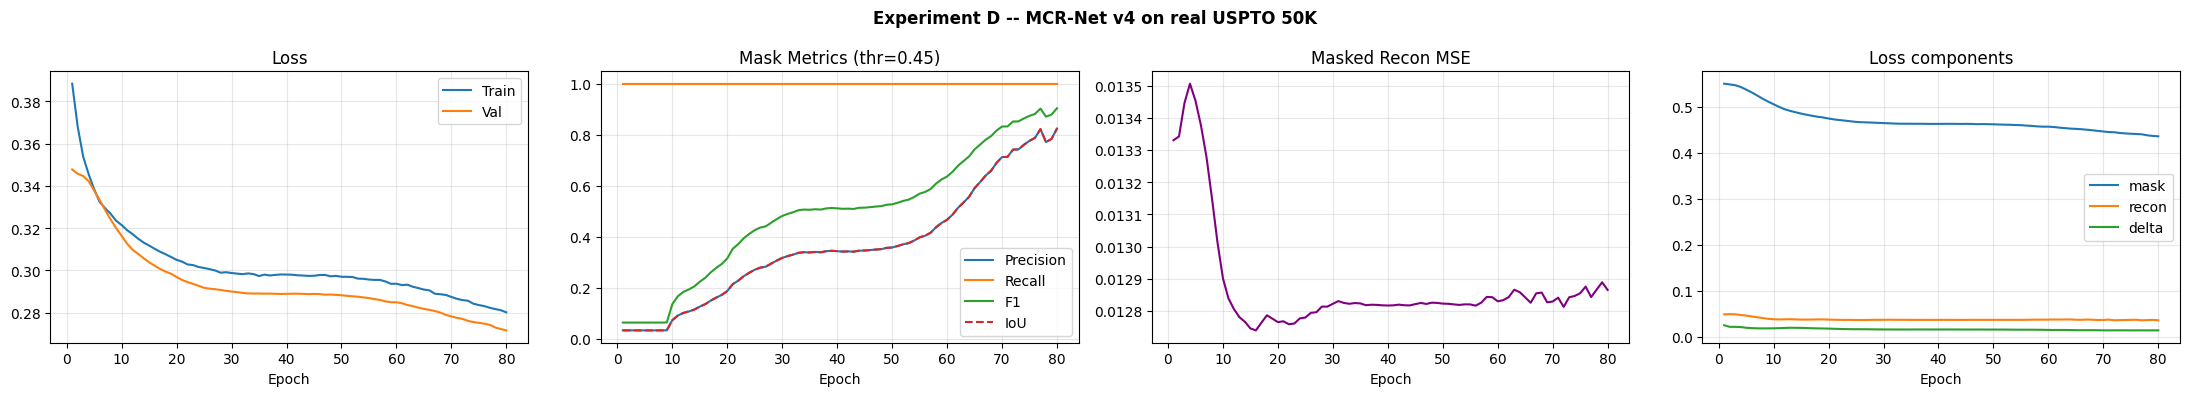

Saved: results/figures/expD_real_training.png


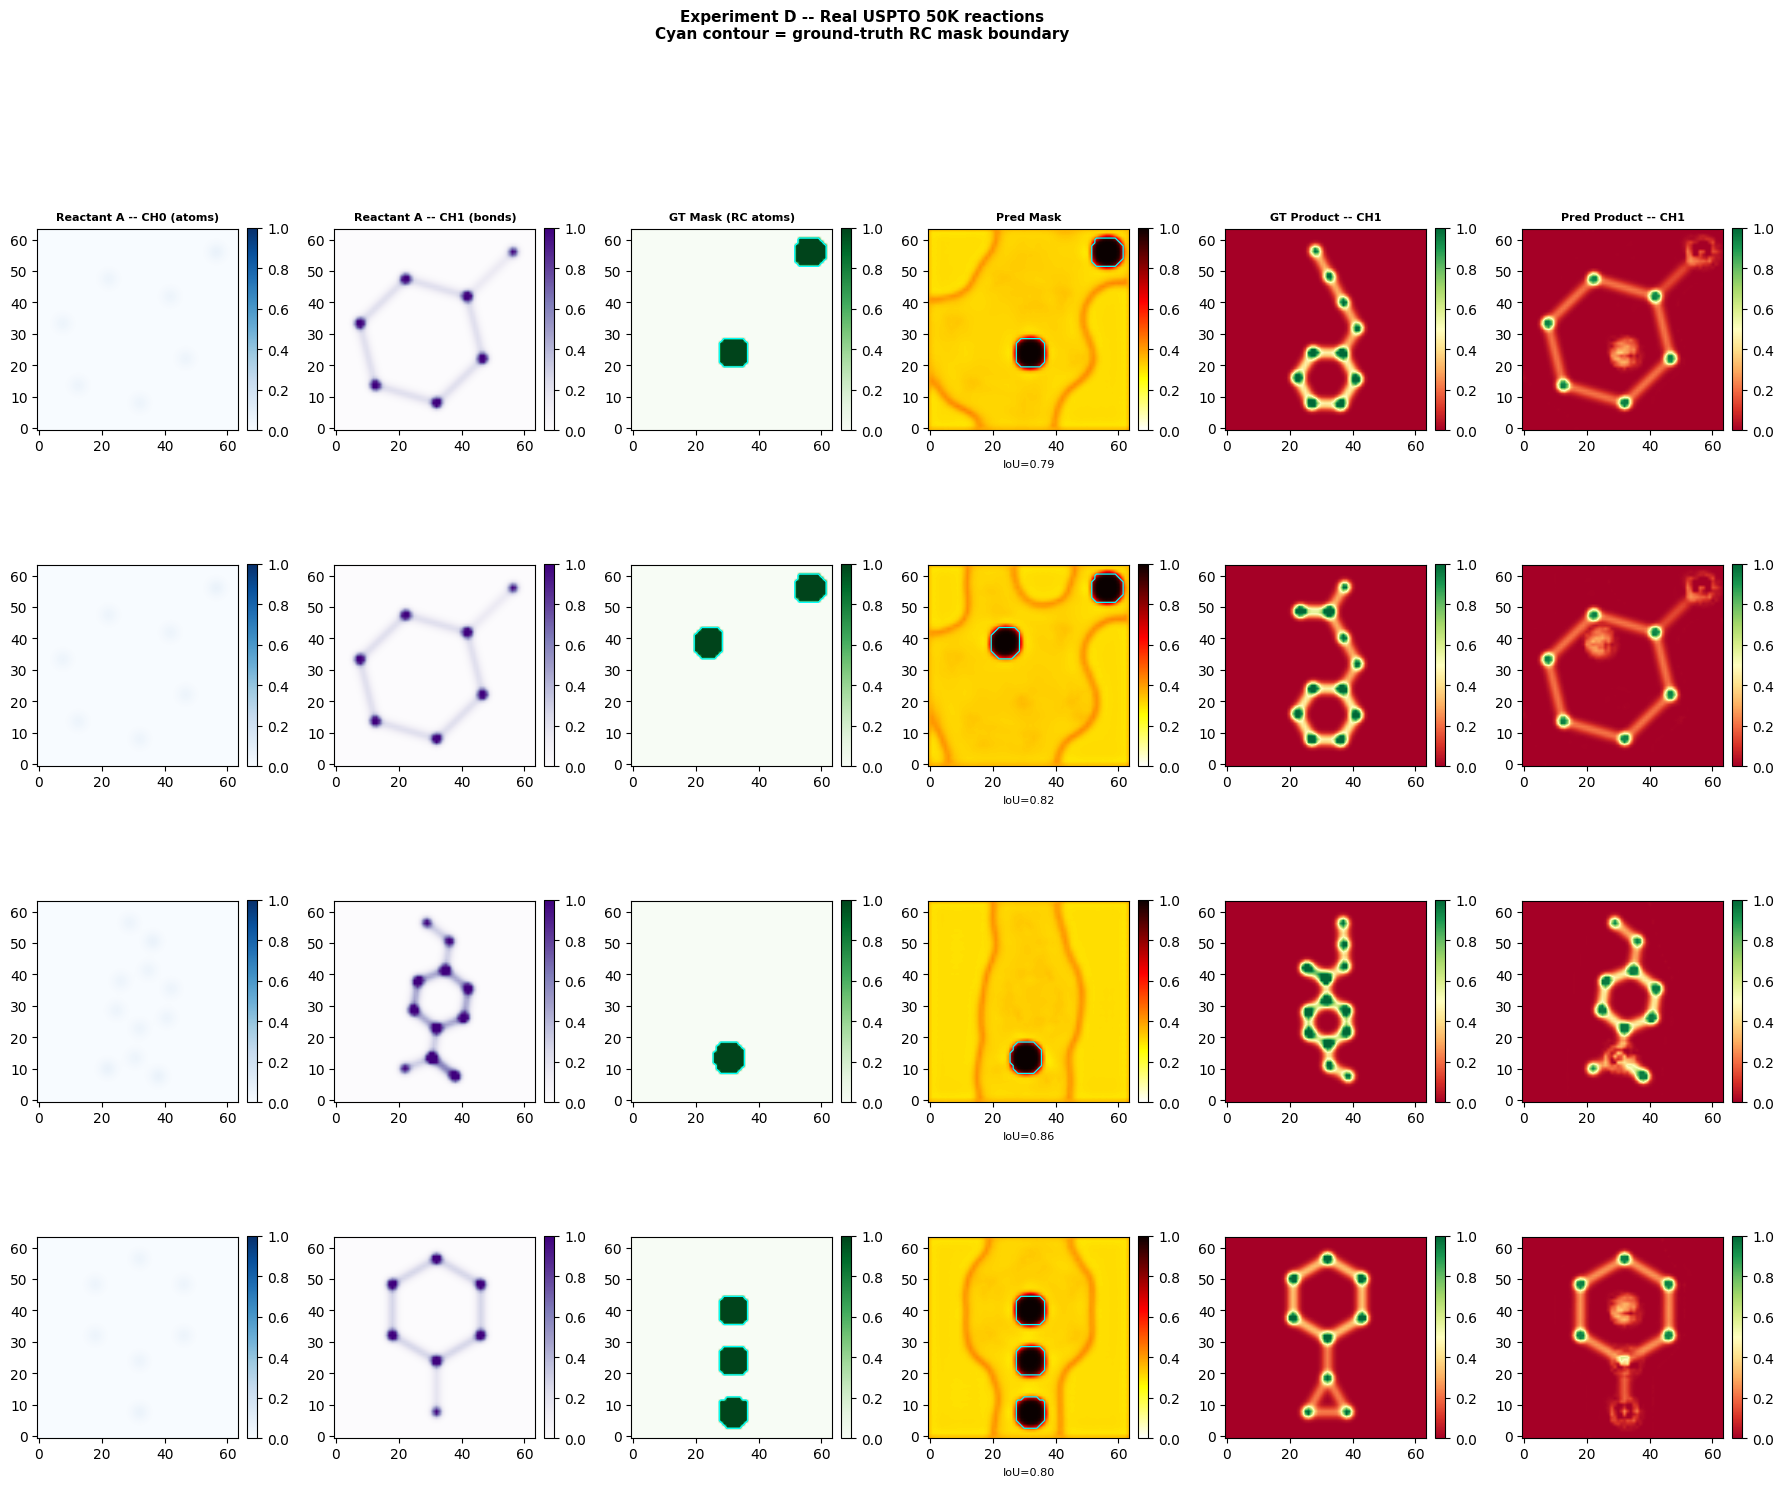

Saved: results/figures/expD_real_heatmaps.png


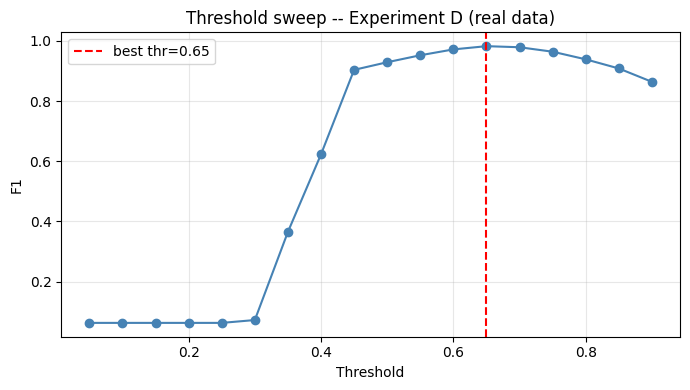

Saved: results/figures/expD_threshold_sweep.png

Experiment D -- MCR-Net v4 on real USPTO 50K  |  Final Eval
  Grid               : 64x64
  Optimal threshold  : 0.65
  Pixel Precision    : 0.978
  Pixel Recall       : 0.987
  Pixel F1           : 0.982
  Pixel IoU          : 0.965
  Reaction Ctr Recall: 1.000
  Tensor MSE         : 0.01287
  Tensor MAE         : 0.02928


{'precision': 0.9777777777726044,
 'recall': 0.9866524292526073,
 'f1': 0.9821950521301464,
 'iou': 0.965013054825248,
 'center_recall': 1.0,
 'mse': 0.012865095399320126,
 'mae': 0.02928238920867443}

In [21]:
# ================================================================
#  CELL D7 -- Visualisation (real data)
# ================================================================

def plot_history_real(h, save='results/figures/expD_real_training.png'):
    ep  = range(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 4, figsize=(22, 4))
    ax[0].plot(ep, h['train_loss'], label='Train')
    ax[0].plot(ep, h['val_loss'],   label='Val')
    ax[0].set_title('Loss'); ax[0].legend(); ax[0].grid(alpha=0.3)
    ax[1].plot(ep, h['precision'], label='Precision')
    ax[1].plot(ep, h['recall'],    label='Recall')
    ax[1].plot(ep, h['f1'],        label='F1')
    ax[1].plot(ep, h['iou'],       label='IoU', linestyle='--')
    ax[1].set_title(f'Mask Metrics (thr={THRESHOLD})')
    ax[1].legend(); ax[1].grid(alpha=0.3)
    ax[2].plot(ep, h['recon_mse'], color='purple')
    ax[2].set_title('Masked Recon MSE'); ax[2].grid(alpha=0.3)
    ax[3].plot(ep, h['l_mask'],  label='mask')
    ax[3].plot(ep, h['l_recon'], label='recon')
    ax[3].plot(ep, h['l_delta'], label='delta')
    ax[3].set_title('Loss components'); ax[3].legend(); ax[3].grid(alpha=0.3)
    for a in ax:
        a.set_xlabel('Epoch')
    plt.suptitle('Experiment D -- MCR-Net v4 on real USPTO 50K',
                 fontweight='bold')
    plt.tight_layout()
    plt.savefig(save, dpi=150); plt.show()
    print(f'Saved: {save}')


def visualise_real(model, dataset, n=4,
                   save='results/figures/expD_real_heatmaps.png'):
    """Show reactant channels, GT mask, predicted mask, GT/pred bonds."""
    model.eval()
    idxs = np.random.choice(len(dataset), min(n, len(dataset)), replace=False)
    fig  = plt.figure(figsize=(22, 4 * n))
    gs   = gridspec.GridSpec(n, 6, hspace=0.5, wspace=0.35)
    col_titles = [
        'Reactant A -- CH0 (atoms)',
        'Reactant A -- CH1 (bonds)',
        'GT Mask (RC atoms)',
        'Pred Mask',
        'GT Product -- CH1',
        'Pred Product -- CH1',
    ]
    cmaps = ['Blues', 'Purples', 'Greens', 'hot_r', 'RdYlGn', 'RdYlGn']

    with torch.no_grad():
        for row, idx in enumerate(idxs):
            X, tm, Tpt, *_ = dataset[idx]
            mp, _, _, _, Tpp = model(X.unsqueeze(0).to(DEVICE))
            mp  = mp.squeeze().cpu().numpy()
            Tpp = Tpp.squeeze().cpu().numpy()
            X_np, Tp_np = X.numpy(), Tpt.numpy()
            tm_np = tm.squeeze().numpy()

            panels = [X_np[0], X_np[1], tm_np, mp, Tp_np[1], Tpp[1]]
            for col, (data, cmap, title) in enumerate(
                    zip(panels, cmaps, col_titles)):
                ax = fig.add_subplot(gs[row, col])
                im = ax.imshow(data.T, cmap=cmap, origin='lower',
                               vmin=0, vmax=1, interpolation='bilinear')
                if row == 0:
                    ax.set_title(title, fontsize=8, fontweight='bold')
                plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
                if col in [2, 3] and tm_np.max() > 0.1:
                    ax.contour(tm_np.T, levels=[0.5],
                               colors='cyan', linewidths=0.9)
                if col == 3:
                    iou = float(
                        ((mp > THRESHOLD) & (tm_np > 0.5)).sum() /
                        (((mp > THRESHOLD) | (tm_np > 0.5)).sum() + 1e-8))
                    ax.set_xlabel(f'IoU={iou:.2f}', fontsize=8)

    fig.suptitle('Experiment D -- Real USPTO 50K reactions\n'
                 'Cyan contour = ground-truth RC mask boundary',
                 fontsize=11, fontweight='bold', y=1.01)
    plt.savefig(save, dpi=150, bbox_inches='tight')
    plt.show(); print(f'Saved: {save}')


def final_evaluation_real(model, dl_val, ds_val,
                           save='results/figures/expD_threshold_sweep.png'):
    model.eval()
    apm, atm, aTp, aTg = [], [], [], []
    with torch.no_grad():
        for X, mt, Tpt, *_ in dl_val:
            mp, _, _, _, Tpp = model(X.to(DEVICE))
            apm.append(mp.cpu()); atm.append(mt)
            aTp.append(Tpp.cpu()); aTg.append(Tpt)
    apm = torch.cat(apm); atm = torch.cat(atm)
    aTp = torch.cat(aTp); aTg = torch.cat(aTg)

    best_f1, best_thr = 0.0, THRESHOLD
    thr_sweep = np.arange(0.05, 0.95, 0.05)
    f1s = []
    for thr in thr_sweep:
        m = compute_metrics(apm, atm, threshold=float(thr))
        f1s.append(m['f1'])
        if m['f1'] > best_f1:
            best_f1, best_thr = m['f1'], float(thr)

    plt.figure(figsize=(7, 4))
    plt.plot(thr_sweep, f1s, marker='o', color='steelblue')
    plt.axvline(best_thr, color='red', linestyle='--',
                label=f'best thr={best_thr:.2f}')
    plt.xlabel('Threshold'); plt.ylabel('F1')
    plt.title('Threshold sweep -- Experiment D (real data)')
    plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(save, dpi=150); plt.show()
    print(f'Saved: {save}')

    fm  = compute_metrics(apm, atm, threshold=best_thr)
    mse = F.mse_loss(aTp, aTg).item()
    mae = (aTp - aTg).abs().mean().item()

    print('\n' + '=' * 60)
    print('Experiment D -- MCR-Net v4 on real USPTO 50K  |  Final Eval')
    print('=' * 60)
    print(f'  Grid               : {GRID_REAL}x{GRID_REAL}')
    print(f'  Optimal threshold  : {best_thr:.2f}')
    print(f'  Pixel Precision    : {fm["precision"]:.3f}')
    print(f'  Pixel Recall       : {fm["recall"]:.3f}')
    print(f'  Pixel F1           : {fm["f1"]:.3f}')
    print(f'  Pixel IoU          : {fm["iou"]:.3f}')
    print(f'  Reaction Ctr Recall: {fm["center_recall"]:.3f}')
    print(f'  Tensor MSE         : {mse:.5f}')
    print(f'  Tensor MAE         : {mae:.5f}')
    print('=' * 60)
    return {**fm, 'mse': mse, 'mae': mae}


# -- run --
plot_history_real(hist_real)
visualise_real(model_real, ds_val, n=4)
final_evaluation_real(model_real, dl_val, ds_val)

Saved: results/figures/expD_channels_aspirin.png


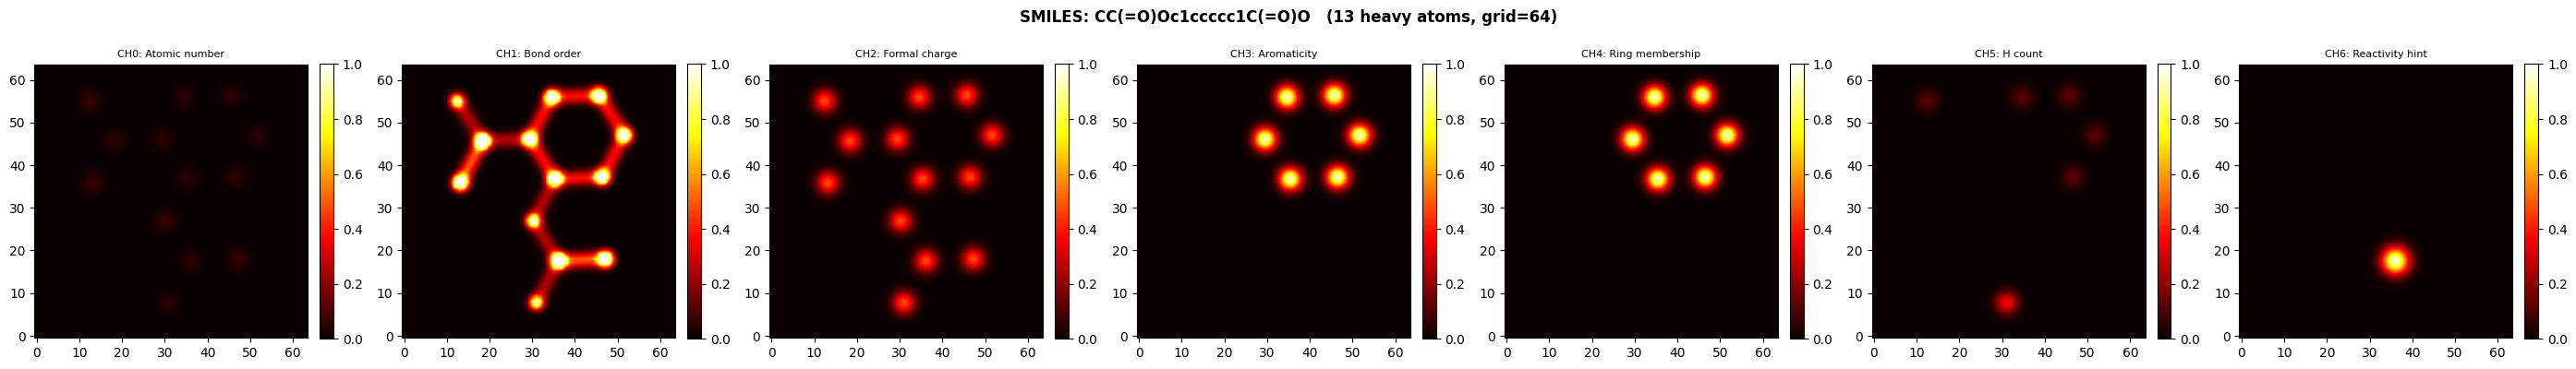

Saved: results/figures/expD_channels_caffeine.png


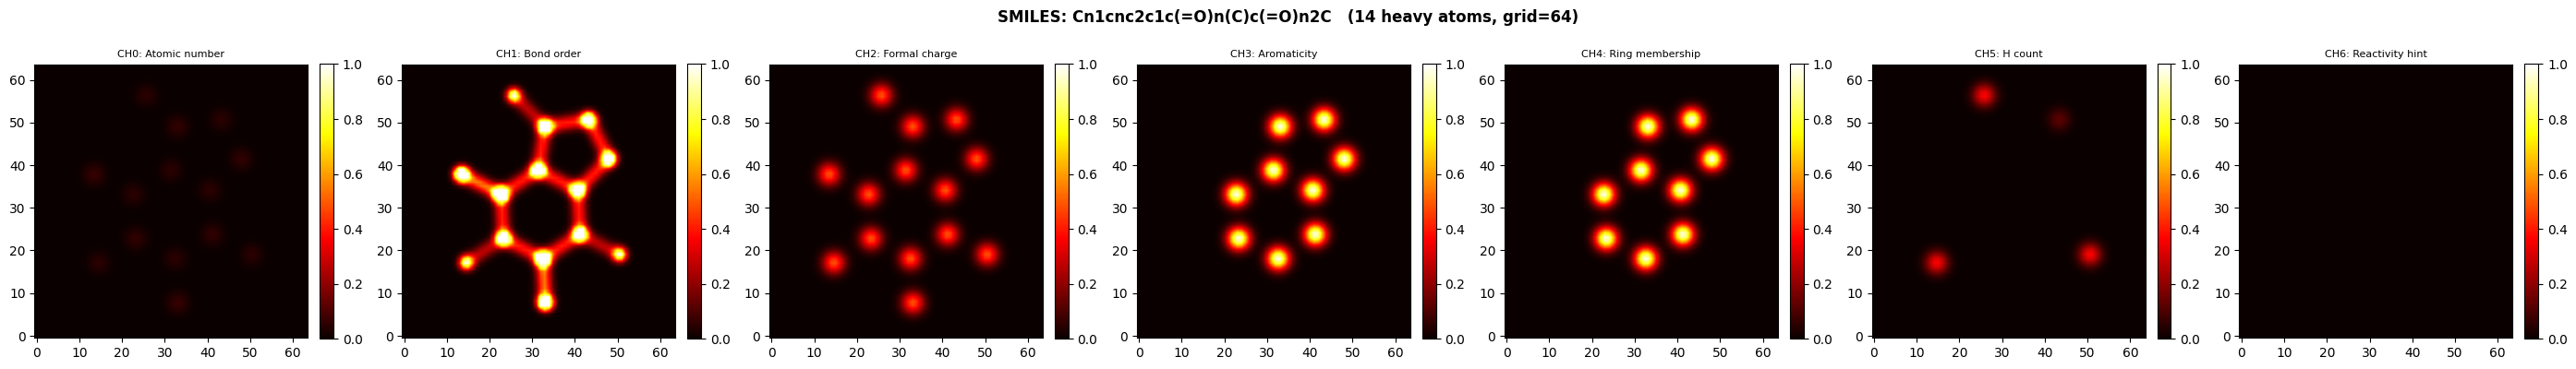

Saved: results/figures/expD_channels_large.png


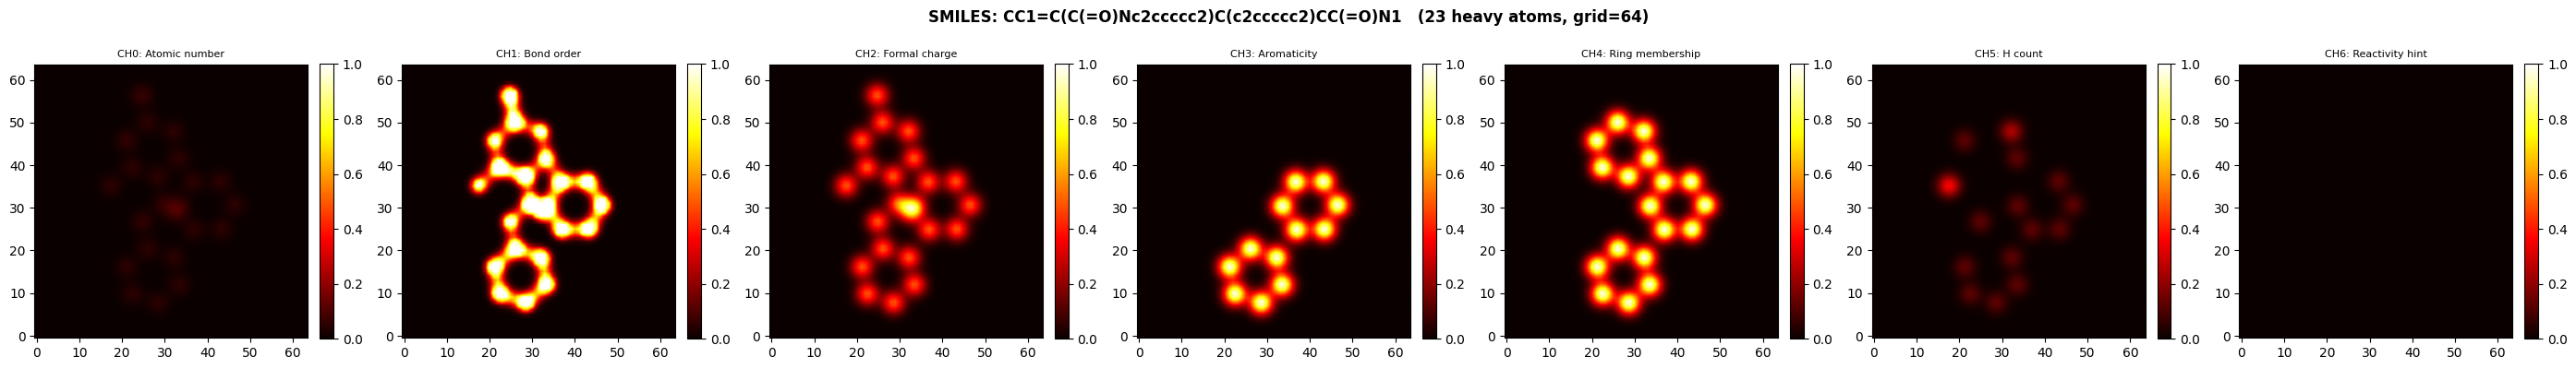

In [22]:
# ================================================================
#  CELL D8 -- Channel sanity check
#
#  Visual proof that smiles_to_tensor produces the expected spatial
#  patterns for each of the 7 channels.  Run this independently of
#  training to verify the representation before committing to a
#  full training run.
# ================================================================

def plot_channels(smi, rc_atoms=None, grid=GRID_REAL, save=None):
    """Render all 7 channels for a single SMILES string."""
    T = smiles_to_tensor(smi, grid=grid, reaction_center_atoms=rc_atoms)
    ch_names = [
        'CH0: Atomic number',
        'CH1: Bond order',
        'CH2: Formal charge',
        'CH3: Aromaticity',
        'CH4: Ring membership',
        'CH5: H count',
        'CH6: Reactivity hint',
    ]
    fig, axes = plt.subplots(1, 7, figsize=(28, 4))
    for i, (ax, name) in enumerate(zip(axes, ch_names)):
        im = ax.imshow(T[i].T, origin='lower', cmap='hot',
                       vmin=0, vmax=1, interpolation='bilinear')
        ax.set_title(name, fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    mol     = Chem.MolFromSmiles(smi)
    n_atoms = mol.GetNumAtoms() if mol else '?'
    plt.suptitle(f'SMILES: {smi}   ({n_atoms} heavy atoms, grid={grid})',
                 fontweight='bold')
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=150, bbox_inches='tight')
        print(f'Saved: {save}')
    plt.show()


# -- expected visual patterns --
# CH0: sharp blobs at atom positions, height ~ atomic number / 118
# CH1: lines connecting atoms + blobs at atoms, height ~ bond order
# CH2: blobs only at charged atoms (most neutral -> CH2 ~ 0.5 uniform)
# CH3: blobs at aromatic atoms only (ring systems lit up)
# CH4: blobs at all ring atoms (larger rings = more coverage)
# CH5: blobs proportional to attached H count
# CH6: only lit when rc_atoms is passed in

# Aspirin: mark C2 (ester carbonyl) as reaction centre
plot_channels('CC(=O)Oc1ccccc1C(=O)O',
              rc_atoms={1},
              save='results/figures/expD_channels_aspirin.png')

# Caffeine: checks aromatic / ring channels (two fused rings)
plot_channels('Cn1cnc2c1c(=O)n(C)c(=O)n2C',
              save='results/figures/expD_channels_caffeine.png')

# Larger molecule (20+ atoms): grid resolution stress test
plot_channels('CC1=C(C(=O)Nc2ccccc2)C(c2ccccc2)CC(=O)N1',
              save='results/figures/expD_channels_large.png')